In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) -- 
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
# 1. Silence C++ backend warnings (Must be before importing/using TF operations)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

try:
    import tensorflow as tf
except:
    !uv pip install tensorflow
    import tensorflow as tf

import logging

# 2. Silence Python level TensorFlow/ABSL warnings
tf.get_logger().setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)

I0000 00:00:1795218382.617287      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795218398.746716      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
## -- keras library --
try:
    from scikeras.wrappers import KerasClassifier
except:
    !uv pip install -q scikeras
    from scikeras.wrappers import KerasClassifier

print()
!pip show scikeras


Name: scikeras
Version: 0.13.0
Summary: Scikit-Learn API wrapper for Keras.
Home-page: https://github.com/adriangb/scikeras
Author: Adrian Garcia Badaracco
Author-email: 1755071+adriangb@users.noreply.github.com
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: keras, scikit-learn
Required-by: 


In [4]:
!uv pip install -q ipywidgets
!uv pip install -q pygraphviz

!apt-get install -qq -y graphviz graphviz-dev && pip install -q pydot

Selecting previously unselected package at-spi2-common.
(Reading database ... 125687 files and directories currently installed.)
Preparing to unpack .../00-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatk1.0-0t64:amd64.
Preparing to unpack .../01-libatk1.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatk1.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libgtk2.0-common.
Preparing to unpack .../02-libgtk2.0-common_2.24.33-4ubuntu1.1_all.deb ...
Unpacking libgtk2.0-common (2.24.33-4ubuntu1.1) ...
Selecting previously unselected package libxcomposite1:amd64.
Preparing to unpack .../03-libxcomposite1_1%3a0.4.5-1build3_amd64.deb ...
Unpacking libxcomposite1:amd64 (1:0.4.5-1build3) ...
Selecting previously unselected package libgtk2.0-0t64:amd64.
Preparing to unpack .../04-libgtk2.0-0t64_2.24.33-4ubuntu1.1_amd64.deb ...
Unpacking libgtk2.0-0t64:amd64 (2.24.33-4ubuntu1.1) ...
Sele

In [5]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [6]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import (StandardScaler, KBinsDiscretizer, OneHotEncoder,
                                    LabelEncoder, TargetEncoder as skTE)

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
# tf.get_logger().setLevel('ERROR')
warnings.simplefilter('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [7]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [8]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
    
## =================================================================================

ID = 'id'
TARGET = 'is_fraud'

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]
int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    # 'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [9]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

In [10]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

print("- Helper Functions Ready -")

- Helper Functions Ready -


In [11]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [12]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [13]:
%%time

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('merchant_category', 'card_type', 'txn_count_last_24h'),
    ('merchant_category', 'customer_age'),
]
def feature_engineering(df, fit=False):
    # Digit extraction
    for col in ['amount_usd', 'hours_since_last_txn',
                'velocity_score', 'distance_from_home_km']:
        decimal_name = f"_{col}_decimal"
        df[decimal_name] = (df[col] % 1).round(2).astype('float32')

    # Categorize numericals
    for col in num_cols + ['_amount_usd_decimal', '_hours_since_last_txn_decimal',
                           '_velocity_score_decimal', '_distance_from_home_km_decimal']:
        cat_name = f"{col}_cat_" if col in num_cols else f"{col[1:]}_cat_"
        values = np.floor(df[col]) if col in num_cols else df[col]
        if fit:
            codes, uniques = values.factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = values.map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Discretize numericals
    bin_config = {'merchant_risk_score': [7], 'hours_since_last_txn': [500, 1000]}
    for col, bins_list in bin_config.items():
        for n_bins in bins_list:
            for strategy in ['quantile']:
                bin_name = f"{col}_{n_bins}_{strategy}_bin_"
                if fit:
                    kb = KBinsDiscretizer(
                        n_bins=n_bins,
                        encode='ordinal',
                        strategy=strategy,
                        subsample=None
                    )
                    binned = kb.fit_transform(df[[col]]).ravel().astype('int32')
                    category_map[bin_name] = kb
                else:
                    kb = category_map[bin_name]
                    binned = kb.transform(df[[col]]).ravel().astype('int32')
                df[bin_name] = binned
                df[bin_name] = df[bin_name].astype('category')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 22
len(new_num_cols): 4 

prep len(cat_cols): 33
prep len(num_cols): 17 

X      prep shape: (699960, 50)
X_test prep shape: (299984, 50) 

----------------------------------------
CPU times: user 2.24 s, sys: 304 ms, total: 2.54 s
Wall time: 2.55 s


In [14]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    pd.concat([X, y], axis=1),
    train_size=90_000,
    stratify=y,
    random_state=42,
)

train_X = pd.concat([X, y], axis=1) if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(699960, 51) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,_amount_usd_decimal,_hours_since_last_txn_decimal,_velocity_score_decimal,_distance_from_home_km_decimal,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd_decimal_cat_,hours_since_last_txn_decimal_cat_,velocity_score_decimal_cat_,distance_from_home_km_decimal_cat_,merchant_risk_score_7_quantile_bin_,hours_since_last_txn_500_quantile_bin_,hours_since_last_txn_1000_quantile_bin_,merchant_category_card_type_txn_count_last_24h_,merchant_category_customer_age_,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.16,0.77,0.5,0.78,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,371,553,0,0,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.83,0.54,0.4,0.06,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,2,80,104,1,1,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.36,0.20,0.8,0.17,2,1,2,2,2,2,2,0,2,2,2,1,0,2,2,2,2,1,59,79,2,2,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.44,0.13,0.7,0.67,3,2,2,2,0,3,3,0,3,3,0,2,0,3,3,3,3,5,251,338,3,3,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.85,0.80,0.8,0.69,4,3,2,3,3,4,4,0,4,4,3,3,0,4,4,2,4,5,42,54,4,4,0.0


In [15]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
import_cols  = base_cols

if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, X_test, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype(int)
else:
    X = train_X[FEATURES]
    X_test = X_test[FEATURES]
    y = train_X[TARGET].astype(int)

print(X.shape, X_test.shape, type(X))

(699960, 50) (299984, 50) <class 'pandas.core.frame.DataFrame'>


# ML TRAINING

In [16]:
## -- SAMPLE MLP VIEWER --
n_features = len(FEATURES)
units = [256, 128, 64]

seq_layers = []
seq_layers.append(tf.keras.Input(shape=(n_features,)))
seq_layers.append(tf.keras.layers.BatchNormalization())

for i in range(len(units)):
    if i < (len(units) - 1):
        d = max(64, units[0] // (2**i))
    else:
        d = 64

    seq_layers.append(tf.keras.layers.Dense(units=d, activation='relu'))
    seq_layers.append(tf.keras.layers.BatchNormalization())
    seq_layers.append(tf.keras.layers.Dropout(0.1))

# Final output layer
seq_layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))

# 3. Create the Sequential model for the "head"
model = tf.keras.Sequential(seq_layers)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name='auc')]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 50)             │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        13,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,265 (219.79 KB)

 Trainable params: 55,269 (215.89 KB)

 Non-trainable params: 996 (3.89 KB)

In [17]:
def keras_mlp(meta, lr, units, act, drop):
    print(f"⚡️ Keras MLP Build")
    # SciKeras passes feature count after ColumnTransformer transformations in meta
    n_features = meta["n_features_in_"]
    seq_layers = []

    # 1. Add Input and the critical initial BatchNormalization layer
    seq_layers.append(tf.keras.Input(shape=(n_features,)))
    seq_layers.append(tf.keras.layers.BatchNormalization())

    # 2. Loop explicitly over your units list to match the architecture
    for u in units:
        seq_layers.append(tf.keras.layers.Dense(units=u, activation=act))
        seq_layers.append(tf.keras.layers.BatchNormalization())
        seq_layers.append(tf.keras.layers.Dropout(drop))

    # 3. Final output layer
    seq_layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))

    # Compile model
    model = tf.keras.Sequential(seq_layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

print("⚙️ Keras MLP model ⚙️")

⚙️ Keras MLP model ⚙️


In [18]:
def keras_seq(meta, lr, units, act, drop):
    print(f"⚡️ Keras SEQUENTIAL Build")
    # SciKeras passes feature count after ColumnTransformer transformations in meta
    n_features = meta["n_features_in_"]

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dense(units[0], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(units[1], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(units[2], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

print("⚙️ Keras SEQUENTIAL model ⚙️")

⚙️ Keras SEQUENTIAL model ⚙️


In [19]:
if "digit_cols" in globals():
    print("✓ digit_cols available!")
else:
    print("𝗫 digit_cols unavailable!")

𝗫 digit_cols unavailable!


In [20]:
CHECKPOINT = "checkpoints/"
shutil.rmtree(CHECKPOINT, ignore_errors=True)
os.makedirs(CHECKPOINT, exist_ok=True)

class CFG:
    TE    = True
    FOLDS = 5
    SEED  = 42
    ACT   = 'relu' # 'relu', 'selu', 'gelu'
    LR    = 0.01
    EPOCH = 15
    STOP  = 5
    DROP  = 0.15
    UNITS = [512, 256, 128]
    BATCH = 1024 if torch.cuda.is_available() else 128

# -- Callbacks --
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        patience=CFG.STOP,
        mode="max",
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ModelCheckpoint( # -> save model
        filepath=f"{CHECKPOINT}best_model.model.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        # verbose=1
    ),
    # tf.keras.callbacks.ModelCheckpoint( # -> save weights
    #     filepath=f"{CHECKPOINT}best_model.weights.h5",
    #     monitor='val_auc' if self.eval_metric == 'auc' else 'val_loss',
    #     save_best_only=True,
    #     save_weights_only=True,
    # ),
    # tf.keras.callbacks.ReduceLROnPlateau(
    #     monitor='val_auc' if self.eval_metric == 'auc' else 'val_loss',
    #     factor=0.5,
    #     patience=5,
    #     min_lr=1e-6,
    #     verbose=1
    # ),
]

keras_params = {
    'model': keras_mlp,
    # model__shape=X_train.shape[1:],
    'batch_size': CFG.BATCH,
    'units': CFG.UNITS,
    'act': CFG.ACT ,
    'drop': CFG.DROP,
    'epochs': CFG.EPOCH,
    'lr': CFG.LR,
    # ---------------------------------------------------------
    # 'optimizer': tf.keras.optimizers.RMSprop(self.learning_rate),
    # 'optimizer': tf.keras.optimizers.Adam(self.learning_rate), # , weight_decay=None
    # 'loss': "binary_crossentropy",
    # 'metrics': [tf.keras.metrics.AUC(name=self.eval_metric)],
    # ---------------------------------------------------------
    # fit__batch_size=GLOBAL_BATCH_SIZE,
    'validation_batch_size': 4096,
    'predict__batch_size': 10240,
    'random_state': 42,
    'shuffle': True,
    'verbose': 1,
    'callbacks': callbacks,
    # class_weight=get_weights(y_train, y_train),
}

keras_params

{'model': <function __main__.keras_mlp(meta, lr, units, act, drop)>,
 'batch_size': 128,
 'units': [512, 256, 128],
 'act': 'relu',
 'drop': 0.15,
 'epochs': 15,
 'lr': 0.01,
 'validation_batch_size': 4096,
 'predict__batch_size': 10240,
 'random_state': 42,
 'shuffle': True,
 'verbose': 1,
 'callbacks': [<keras.src.callbacks.early_stopping.EarlyStopping at 0x78a33a4cc2f0>,
  <keras.src.callbacks.model_checkpoint.ModelCheckpoint at 0x78a33a4cd400>]}

In [21]:
get_cats_ = [c for c in cat_cols if (c.endswith(("_cat_", "_bin_"))) | (X[c].dtype in ['category', 'bool', 'object'])]
get_cats_

['merchant_category',
 'card_type',
 'auth_method',
 'channel',
 'device_type',
 'is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt',
 'amount_usd_cat_',
 'hours_since_last_txn_cat_',
 'txn_count_last_24h_cat_',
 'distance_from_home_km_cat_',
 'card_age_months_cat_',
 'customer_age_cat_',
 'account_balance_usd_cat_',
 'cvv_retry_count_cat_',
 'velocity_score_cat_',
 'time_of_day_hour_cat_',
 'day_of_week_cat_',
 'merchant_risk_score_cat_',
 'prior_disputes_cat_',
 'amount_usd_decimal_cat_',
 'hours_since_last_txn_decimal_cat_',
 'velocity_score_decimal_cat_',
 'distance_from_home_km_decimal_cat_',
 'merchant_risk_score_7_quantile_bin_',
 'hours_since_last_txn_500_quantile_bin_',
 'hours_since_last_txn_1000_quantile_bin_',
 'merchant_category_card_type_txn_count_last_24h_',
 'merchant_category_customer_age_']

In [22]:
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = f"KERAS{CFG.ACT[:2]}_mlp({X.shape[1]}_{CFG.UNITS[0]}_{str(CFG.DROP).split('.')[1]})"
print(f"🚀 Training {model_name} with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
best_iterations = []

_cats_ = [c for c in cat_cols if c.endswith(("_cat_", "_bin_"))] #

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = combo_names + _cats_
        smooth  = 'auto'
        print(f"⚡️ TargetEncoding ({len(te_cols)}) • smooth={smooth}")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop )
        X_val = X_val.drop(columns=combos_to_drop )
        X_tst = X_tst.drop(columns=combos_to_drop )

    ## -- Define encoders --
    scaler_enc  = StandardScaler()
    ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
    num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=9)
    cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
    ## ------------------------------------------------------------------------
    all_cats = [c for c in cat_cols if c not in combos_to_drop ]
    all_nums = [c for c in X_trn.columns if c not in all_cats]

    num_proc = make_pipeline(scaler_enc)
    cat_proc = make_pipeline(ohe_enc)

    preprocessor = make_column_transformer(
        (num_proc, all_nums),
        (cat_proc, all_cats),
        remainder='passthrough',
        verbose_feature_names_out=False,
        n_jobs=-1,
    )
    X_trn = preprocessor.fit_transform(X_trn, y_trn)
    X_val = preprocessor.transform(X_val)
    X_tst = preprocessor.transform(X_tst)
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")
    seeder = 42 #+ (fold-1)

    model = KerasClassifier(**keras_params)
    model.random_state = seeder
    model.fit(X_trn, y_trn, validation_data=(X_val, y_val))

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds
    
    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model.callbacks[0].stopped_epoch
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("-"*22)
    print(f"{Fore.YELLOW}{Style.BRIGHT}# Model best: {model.callbacks[0].best:.5f}{Style.RESET_ALL}")
    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed={seeder}, iter={best_iter}, time={ff} mins ]\n")

test_preds /= FOLDS
# model_name = f"KERAS{CFG.ACT[:2]}_mlp({X_trn.shape[1]}_{CFG.UNITS[0]}_{str(CFG.DROP).split('.')[1]})"

# model_name = model_name + f"({X_tr.shape[1]})"
# features_used = X_tr.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s} @ epoch={t}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'epoch'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_trn, X_val, y_trn, y_val, model

🚀 Training KERASre_mlp(50_512_15) with 5 Folds
### Fold 1/5
⚡️ TargetEncoding (22) • smooth=auto
train=(559968, 80), valid=(139992, 80)

⚡️ Keras MLP Build
Epoch 1/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 43s 9ms/step - auc: 0.9193 - loss: 0.0531 - val_auc: 0.9314 - val_loss: 0.0468
Epoch 2/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 39s 9ms/step - auc: 0.9285 - loss: 0.0489 - val_auc: 0.9323 - val_loss: 0.0466
Epoch 3/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 39s 9ms/step - auc: 0.9305 - loss: 0.0481 - val_auc: 0.9258 - val_loss: 0.0468
Epoch 4/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 39s 9ms/step - auc: 0.9324 - loss: 0.0477 - val_auc: 0.9286 - val_loss: 0.0464
Epoch 5/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 39s 9ms/step - auc: 0.9333 - loss: 0.0473 - val_auc: 0.9216 - val_loss: 0.0478
Epoch 6/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 42s 10ms/step - auc: 0.9341 - loss: 0.0470 - val_auc: 0.9244 - val_loss: 0.0467
Epoch 7/15
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 41s 9ms/step - auc: 0.9349 - loss: 0.0467 - val_auc: 0.9109 - val_loss: 9.9

In [23]:
# dir(preprocessor)

In [24]:
# ============================================= GELU
# 5-FOLD CV: KERASgelu_mlp(50_256_1) | (559968, 80)
# ==================================================
#  • Fold 1 AUC: 0.94674 @ epoch=3
#  • Fold 2 AUC: 0.94679 @ epoch=3
#  • Fold 3 AUC: 0.95146 @ epoch=3
#  • Fold 4 AUC: 0.94705 @ epoch=4
#  • Fold 5 AUC: 0.93922 @ epoch=2
# --------------------------------------------------
# OOF score: 0.94495
# AVG score: 0.94625 ± 0.00394
# --------------------------------------------------
# 14.04 mins

# ============================================= SELU
# 5-FOLD CV: KERASselu_mlp(50_256_1) | (559968, 80)
# ==================================================
#  • Fold 1 AUC: 0.94697 @ epoch=3
#  • Fold 2 AUC: 0.94785 @ epoch=4
#  • Fold 3 AUC: 0.95148 @ epoch=2
#  • Fold 4 AUC: 0.94718 @ epoch=5
#  • Fold 5 AUC: 0.94005 @ epoch=2
# --------------------------------------------------
# OOF score: 0.94494
# AVG score: 0.94671 ± 0.00371
# --------------------------------------------------
# 12.91 mins

# ============================================= RELU
# 5-FOLD CV: KERASrelu_mlp(50_256_1) | (559968, 80)
# ==================================================
#  • Fold 1 AUC: 0.94754
#  • Fold 2 AUC: 0.94653
#  • Fold 3 AUC: 0.95106
#  • Fold 4 AUC: 0.94769
#  • Fold 5 AUC: 0.93929
# --------------------------------------------------
# OOF score: 0.94429
# AVG score: 0.94642 ± 0.00388
# --------------------------------------------------
# 11.68 mins

# ==================================================
# 5-FOLD CV: KERASre_mlp(50_512_15) | (559968, 80)
# ==================================================
#  • Fold 1 AUC: 0.94707 @ epoch=4
#  • Fold 2 AUC: 0.94778 @ epoch=4
#  • Fold 3 AUC: 0.95104 @ epoch=2
#  • Fold 4 AUC: 0.94767 @ epoch=6
#  • Fold 5 AUC: 0.94031 @ epoch=2
# --------------------------------------------------
# OOF score: 0.94522
# AVG score: 0.94677 ± 0.00352
# --------------------------------------------------
# 18.58 mins

In [25]:
# dir(model)

# dir(model.callbacks[0])
# model.callbacks[0].stopped_epoch

In [26]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
KERASre_mlp(50_512_15)_94677
-------------------------
23 mins



,auc,epoch,time(min)
fold 1,0.94707,6,4.98
fold 2,0.94778,6,4.86
fold 3,0.95104,4,3.53
fold 4,0.94767,8,6.14
fold 5,0.94031,4,3.46


In [27]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000104
1,699961,0.000107
2,699962,0.086863
3,699963,0.000826
4,699964,0.000576


In [28]:
# !rm -r /kaggle/working

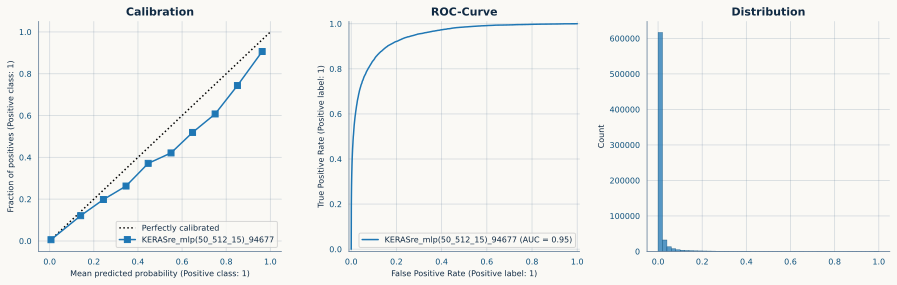

In [29]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()